In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pandas.plotting import scatter_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FactorAnalysis

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

In [43]:
drugcost_df = pd.read_csv("HW4_DrugCost.csv")

print("DrugCost dataset dimensions:", drugcost_df.shape)
display(drugcost_df.head())

DrugCost dataset dimensions: (29, 9)


,COST,RXPM,GS,RI,COPAY,AGE,F,MM,ID
0,1.34,4.2,36,45.6,10.87,29.7,52.3,1158096,MN1
1,1.34,5.4,37,45.6,8.66,29.7,52.3,1049892,MN2
2,1.38,7.0,37,45.6,8.12,29.7,52.3,96168,MN3
3,1.22,7.1,40,23.6,5.89,28.7,53.4,407268,GA
4,1.08,3.5,40,23.6,6.05,28.7,53.4,13224,GA2


In [ ]:
Q1: Scatter Plot matrix

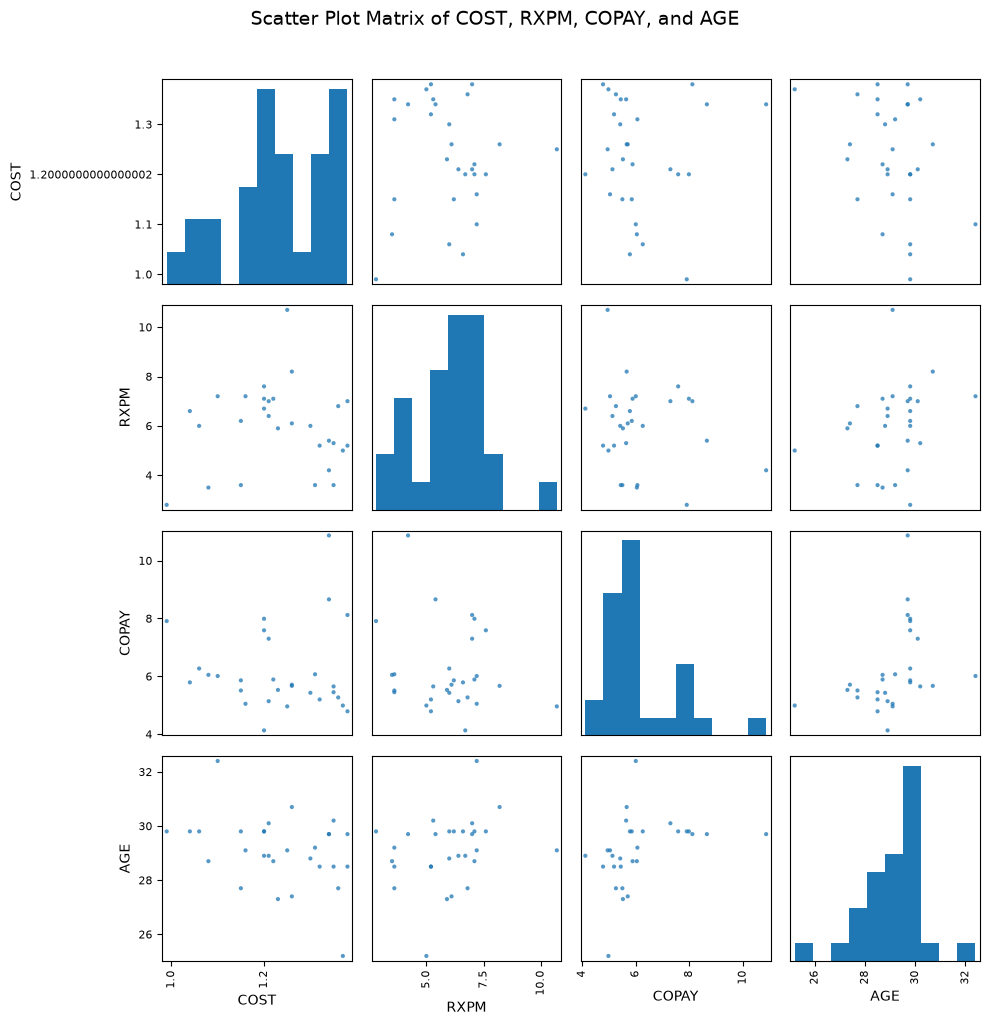

In [6]:
scatter_variables = ["COST", "RXPM", "COPAY", "AGE"]

scatter_matrix(
    drugcost_df[scatter_variables],
    figsize=(10, 10),
    diagonal="hist",
    alpha=0.75
)

plt.suptitle(
    "Scatter Plot Matrix of COST, RXPM, COPAY, and AGE",
    y=1.02,
    fontsize=14
)

plt.tight_layout()
plt.show()

In [ ]:
Correlation Matrix

In [7]:
correlation_matrix = drugcost_df[scatter_variables].corr()

display(correlation_matrix)

,COST,RXPM,COPAY,AGE
COST,1.000000,0.016223,0.009660,-0.348911
RXPM,0.016223,1.000000,-0.183411,0.259938
COPAY,0.009660,-0.183411,1.000000,0.373081
AGE,-0.348911,0.259938,0.373081,1.000000


In [ ]:
Q2: Mean Cost and Age Variance, Mean Cost and Standard error

In [ ]:
MEAN COST and STANDARD ERROR

In [8]:
n = len(drugcost_df)

mean_cost = drugcost_df["COST"].mean()

cost_standard_deviation = drugcost_df["COST"].std(ddof=1)

cost_standard_error = cost_standard_deviation / np.sqrt(n)

print("Mean COST:", round(mean_cost, 4))
print("Standard deviation of COST:", round(cost_standard_deviation, 4))
print("Standard error of mean COST:", round(cost_standard_error, 4))

Mean COST: 1.2334
Standard deviation of COST: 0.11
Standard error of mean COST: 0.0204


In [ ]:
AGE VARIANCE and STANDARD ERROR

In [9]:
age_variance = drugcost_df["AGE"].var(ddof=1)

# Approximate standard error of the sample variance
age_variance_standard_error = age_variance * np.sqrt(2 / (n - 1))

print("AGE variance:", round(age_variance, 4))
print(
    "Approximate standard error of AGE variance:",
    round(age_variance_standard_error, 4)
)

AGE variance: 1.6612
Approximate standard error of AGE variance: 0.444


In [ ]:
COMBINED RESULTS TABLE

In [10]:
question2_results = pd.DataFrame({
    "Measure": [
        "Mean COST",
        "AGE Variance"
    ],
    "Estimate": [
        mean_cost,
        age_variance
    ],
    "Standard Error": [
        cost_standard_error,
        age_variance_standard_error
    ]
})

display(question2_results)

,Measure,Estimate,Standard Error
0,Mean COST,1.233448,0.020434
1,AGE Variance,1.661232,0.443983


In [ ]:
Q3: Principal Component Analysis
(Excluded COST and ID because COST is the outcome variable and ID is only an identifier)

In [11]:
pca_variables = [
    "RXPM",
    "GS",
    "RI",
    "COPAY",
    "AGE",
    "F",
    "MM"
]

X = drugcost_df[pca_variables]

In [12]:
#Standardizing the variables

scaler = StandardScaler()

X_standardized = scaler.fit_transform(X)

X_standardized_df = pd.DataFrame(
    X_standardized,
    columns=pca_variables
)

display(X_standardized_df.head())

,RXPM,GS,RI,COPAY,AGE,F,MM
0,-1.076473,-0.561818,2.391096,3.332687,0.484649,-0.041345,1.853642
1,-0.347655,-0.388491,2.391096,1.766419,0.484649,-0.041345,1.585177
2,0.624103,-0.388491,2.391096,1.383711,0.484649,-0.041345,-0.781110
3,0.684838,0.131489,0.631558,-0.196730,-0.304947,0.586712,-0.009239
4,-1.501618,0.131489,0.631558,-0.083335,-0.304947,0.586712,-0.986903


In [13]:
#Performing PCA

pca = PCA()

pca_scores = pca.fit_transform(X_standardized)

In [14]:
#Variance explained by each component

pca_variance_table = pd.DataFrame({
    "Component": [
        f"PC{i}" for i in range(1, len(pca_variables) + 1)
    ],
    "Eigenvalue": pca.explained_variance_,
    "Variance Explained": pca.explained_variance_ratio_,
    "Variance Explained Percent":
        pca.explained_variance_ratio_ * 100,
    "Cumulative Variance Percent":
        np.cumsum(pca.explained_variance_ratio_) * 100
})

display(pca_variance_table)

,Component,Eigenvalue,Variance Explained,Variance Explained Percent,Cumulative Variance Percent
0,PC1,2.537672,0.350024,35.002378,35.002378
1,PC2,1.471626,0.202983,20.298292,55.300670
2,PC3,0.936977,0.129238,12.923826,68.224496
3,PC4,0.886667,0.122299,12.229885,80.454381
4,PC5,0.730169,0.100713,10.071301,90.525682
5,PC6,0.494525,0.068210,6.821037,97.346719
6,PC7,0.192363,0.026533,2.653281,100.000000


In [15]:
#PCA Component loadings

pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_variables,
    columns=[
        f"PC{i}" for i in range(1, len(pca_variables) + 1)
    ]
)

display(pca_loadings)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
RXPM,0.117719,0.626312,-0.536601,0.035515,0.299052,-0.388733,0.253235
GS,0.146420,0.523589,0.301800,0.649030,-0.320303,0.298372,0.021734
RI,0.532281,-0.206812,-0.213991,0.293610,-0.037418,-0.312194,-0.665613
COPAY,0.476768,-0.441094,-0.114237,0.225152,-0.167884,-0.064927,0.694251
AGE,0.456784,0.132635,-0.314480,-0.376971,0.034598,0.724360,-0.082803
F,-0.338132,-0.277088,-0.361237,0.546093,0.496534,0.364617,-0.026212
MM,0.362060,0.043395,0.576839,-0.016556,0.728454,-0.023155,0.053207


In [16]:
#PCA Scores

pca_scores_df = pd.DataFrame(
    pca_scores,
    columns=[
        f"PC{i}" for i in range(1, len(pca_variables) + 1)
    ]
)

display(pca_scores_df.head())

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,3.559161,-2.776731,0.447467,0.813576,0.555587,-0.418972,0.496944
1,2.826389,-1.550289,0.132757,0.603752,0.785411,-0.542663,-0.416394
2,1.901583,-0.875540,-1.709937,0.591273,-0.583463,-0.840779,-0.561908
3,0.001217,0.250513,-0.561847,0.686309,0.446124,-0.418135,-0.371291
4,-0.556080,-1.211333,0.034498,0.650373,-0.938961,0.447089,-0.898272


In [ ]:
SCREE PLOT

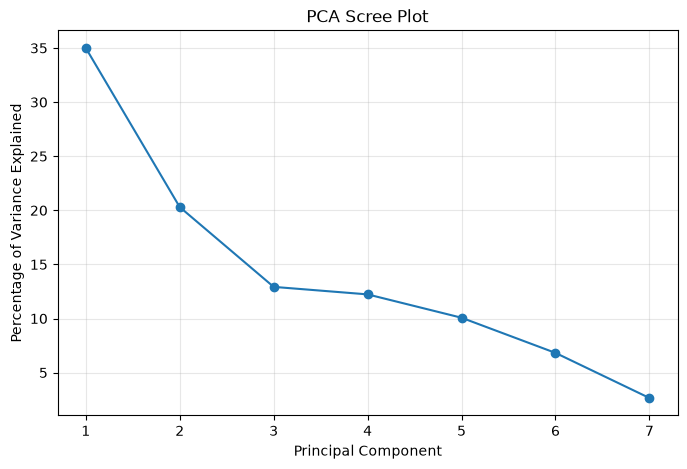

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(pca_variables) + 1),
    pca.explained_variance_ratio_ * 100,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Percentage of Variance Explained")
plt.title("PCA Scree Plot")
plt.xticks(range(1, len(pca_variables) + 1))
plt.grid(alpha=0.30)

plt.show()

In [ ]:
CUMULATIVE VARIANCE PLOT

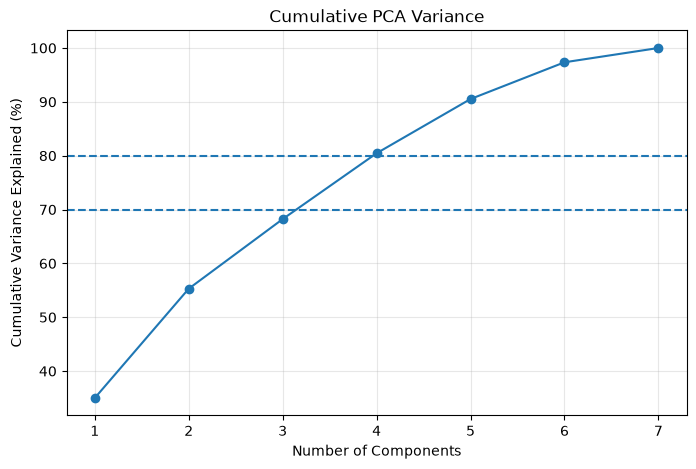

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(pca_variables) + 1),
    np.cumsum(pca.explained_variance_ratio_) * 100,
    marker="o"
)

plt.axhline(70, linestyle="--")
plt.axhline(80, linestyle="--")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance Explained (%)")
plt.title("Cumulative PCA Variance")
plt.xticks(range(1, len(pca_variables) + 1))
plt.grid(alpha=0.30)

plt.show()

In [ ]:
Q4: Factor Analysis

In [19]:
#Performing three-factor analysis

factor_analysis = FactorAnalysis(
    n_components=3,
    rotation="varimax",
    random_state=1
)

factor_scores = factor_analysis.fit_transform(X_standardized)

In [20]:
#Factor loadings

factor_loadings = pd.DataFrame(
    factor_analysis.components_.T,
    index=pca_variables,
    columns=[
        "Factor 1",
        "Factor 2",
        "Factor 3"
    ]
)

display(factor_loadings)

,Factor 1,Factor 2,Factor 3
RXPM,-0.043755,0.820642,-0.075302
GS,0.017230,0.292872,-0.192667
RI,0.866601,0.157644,-0.115179
COPAY,0.899142,-0.178278,-0.062923
AGE,0.419922,0.269205,-0.385426
F,-0.140540,-0.092262,0.692619
MM,0.289297,0.042239,-0.331930


In [21]:
#Factor Scores

factor_scores_df = pd.DataFrame(
    factor_scores,
    columns=[
        "Factor 1",
        "Factor 2",
        "Factor 3"
    ]
)

display(factor_scores_df.head())

,Factor 1,Factor 2,Factor 3
0,2.942623,-1.051592,0.053256
1,2.056120,-0.113162,-0.015426
2,1.822568,0.700629,0.406584
3,0.186062,0.706191,0.495791
4,0.204928,-0.864258,0.482880


In [ ]:
VARIANCE REPRESENTED BY EACH OTHER

In [22]:
factor_ss_loadings = (
    factor_loadings ** 2
).sum(axis=0)

factor_variance_proportion = (
    factor_ss_loadings / len(pca_variables)
)

factor_variance_table = pd.DataFrame({
    "Factor": [
        "Factor 1",
        "Factor 2",
        "Factor 3"
    ],
    "Sum of Squared Loadings":
        factor_ss_loadings.values,
    "Variance Represented":
        factor_variance_proportion.values,
    "Variance Represented Percent":
        factor_variance_proportion.values * 100,
    "Cumulative Variance Percent":
        np.cumsum(
            factor_variance_proportion.values
        ) * 100
})

display(factor_variance_table)

,Factor,Sum of Squared Loadings,Variance Represented,Variance Represented Percent,Cumulative Variance Percent
0,Factor 1,1.841444,0.263063,26.306339,26.306339
1,Factor 2,0.898630,0.128376,12.837571,39.143909
2,Factor 3,0.798468,0.114067,11.406681,50.550591


In [23]:
#Communalities and Uniqueness

communalities = (
    factor_loadings ** 2
).sum(axis=1)

factor_quality_table = pd.DataFrame({
    "Communality": communalities,
    "Uniqueness": factor_analysis.noise_variance_
})

display(factor_quality_table)

,Communality,Uniqueness
RXPM,0.681038,0.325212
GS,0.123192,0.876401
RI,0.789115,0.208833
COPAY,0.844199,0.156952
AGE,0.397359,0.602198
F,0.507984,0.497329
MM,0.195654,0.803573


In [24]:
#Strongest loadings displayed for each factor

for factor in factor_loadings.columns:
    print(f"\n{factor}")
    
    print(
        factor_loadings[factor]
        .sort_values(
            key=lambda values: values.abs(),
            ascending=False
        )
    )


Factor 1
COPAY    0.899142
RI       0.866601
AGE      0.419922
MM       0.289297
F       -0.140540
RXPM    -0.043755
GS       0.017230
Name: Factor 1, dtype: float64

Factor 2
RXPM     0.820642
GS       0.292872
AGE      0.269205
COPAY   -0.178278
RI       0.157644
F       -0.092262
MM       0.042239
Name: Factor 2, dtype: float64

Factor 3
F        0.692619
AGE     -0.385426
MM      -0.331930
GS      -0.192667
RI      -0.115179
RXPM    -0.075302
COPAY   -0.062923
Name: Factor 3, dtype: float64


In [ ]:
Factor 1 explains approximately 26.31% of the total standardized variance. 
It loads strongly on COPAY and RI and moderately on AGE. This factor appears 
represents plan cost and reimbursement characteristics.

Factor 2 explains approximately 12.84% of the total variance. Its strongest 
loading is on RXPM, so it can be interpreted as prescription utilization.

Factor 3 explains approximately 11.41% of total variance. It loads positively 
on F and negatively on AGE and MM. This factor describes member demographic 
composition.

Together, the three factors represent approximately 50.55% of the total 
variance.

PCA expresses the dataset more efficiently because its first three components 
explain approximately 68.22% of total variance, while the first three factors 
represent approximately 50.55%. Factor analysis may be easier to interpret, 
but PCA preserves more information using the same number of dimensions.

In [ ]:
Q5: Multiple Regression

In [25]:
#Cost is the dependent variable

multiple_regression_model = smf.ols(
    formula=(
        "COST ~ RXPM + GS + RI + COPAY "
        "+ AGE + F + MM"
    ),
    data=drugcost_df
).fit()

In [ ]:
REGRESSION SUMARY

In [26]:
print(multiple_regression_model.summary())

                            OLS Regression Results                            
Dep. Variable:                   COST   R-squared:                       0.576
Model:                            OLS   Adj. R-squared:                  0.434
Method:                 Least Squares   F-statistic:                     4.072
Date:                Sun, 19 Jul 2026   Prob (F-statistic):            0.00572
Time:                        21:11:32   Log-Likelihood:                 35.794
No. Observations:                  29   AIC:                            -55.59
Df Residuals:                      21   BIC:                            -44.65
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.8507      0.764      2.424      0.0

In [ ]:
ANOVA TABLE

In [27]:
multiple_regression_anova = anova_lm(
    multiple_regression_model
)

display(multiple_regression_anova)

,df,sum_sq,mean_sq,F,PR(>F)
RXPM,1.0,0.000089,0.000089,0.013029,0.910208
GS,1.0,0.120145,0.120145,17.541629,0.000414
RI,1.0,0.000008,0.000008,0.001172,0.973012
COPAY,1.0,0.000331,0.000331,0.048355,0.828075
AGE,1.0,0.060754,0.060754,8.870314,0.007168
F,1.0,0.010553,0.010553,1.540781,0.228189
MM,1.0,0.003342,0.003342,0.487956,0.492505
Residual,21.0,0.143832,0.006849,NaN,NaN


In [ ]:
REGRESSION COEFFICIENTS

In [28]:
regression_coefficients = pd.DataFrame({
    "Coefficient":
        multiple_regression_model.params,
    "Standard Error":
        multiple_regression_model.bse,
    "t Statistic":
        multiple_regression_model.tvalues,
    "p-value":
        multiple_regression_model.pvalues
})

display(regression_coefficients)

,Coefficient,Standard Error,t Statistic,p-value
Intercept,1.850704e+00,7.636373e-01,2.423538,0.024488
RXPM,2.241353e-02,1.100477e-02,2.036710,0.054483
GS,-1.137248e-02,2.830225e-03,-4.018224,0.000622
RI,3.340828e-04,2.088993e-03,0.159925,0.874468
COPAY,1.472475e-02,1.869824e-02,0.787494,0.439791
AGE,-3.754176e-02,1.491306e-02,-2.517375,0.020012
F,1.296648e-02,9.712233e-03,1.335067,0.196148
MM,2.908008e-08,4.162990e-08,0.698538,0.492505


In [ ]:
PREDICTED VALUES and RESIDUALS

In [29]:
drugcost_df["OLS_Predicted_COST"] = (
    multiple_regression_model.predict(drugcost_df)
)

drugcost_df["OLS_Residual"] = (
    drugcost_df["COST"]
    - drugcost_df["OLS_Predicted_COST"]
)

display(
    drugcost_df[
        [
            "COST",
            "OLS_Predicted_COST",
            "OLS_Residual"
        ]
    ].head()
)

,COST,OLS_Predicted_COST,OLS_Residual
0,1.34,1.307559,0.032441
1,1.34,1.287394,0.052606
2,1.38,1.287570,0.092430
3,1.22,1.276360,-0.056360
4,1.08,1.186568,-0.106568


In [30]:
#Model performance measures

ols_actual = drugcost_df["COST"]
ols_predictions = drugcost_df["OLS_Predicted_COST"]

ols_rmse = np.sqrt(
    np.mean(
        (ols_actual - ols_predictions) ** 2
    )
)

ols_mae = np.mean(
    np.abs(
        ols_actual - ols_predictions
    )
)

ols_metrics = pd.DataFrame({
    "Measure": [
        "R-squared",
        "Adjusted R-squared",
        "F statistic",
        "Overall F-test p-value",
        "RMSE",
        "MAE",
        "AIC",
        "BIC"
    ],
    "Value": [
        multiple_regression_model.rsquared,
        multiple_regression_model.rsquared_adj,
        multiple_regression_model.fvalue,
        multiple_regression_model.f_pvalue,
        ols_rmse,
        ols_mae,
        multiple_regression_model.aic,
        multiple_regression_model.bic
    ]
})

display(ols_metrics)

,Measure,Value
0,R-squared,0.575785
1,Adjusted R-squared,0.434380
2,F statistic,4.071891
3,Overall F-test p-value,0.005720
4,RMSE,0.070425
5,MAE,0.057781
6,AIC,-55.587277
7,BIC,-44.648910


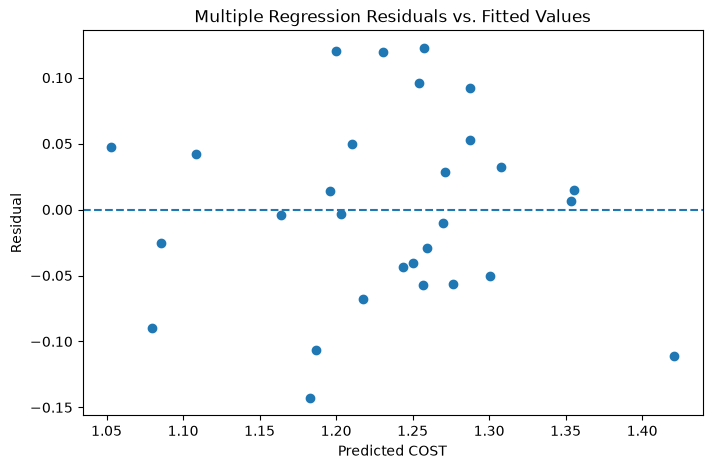

In [31]:
#Residual versus fitted plot

plt.figure(figsize=(8, 5))

plt.scatter(
    multiple_regression_model.fittedvalues,
    multiple_regression_model.resid
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted COST")
plt.ylabel("Residual")
plt.title("Multiple Regression Residuals vs. Fitted Values")

plt.show()

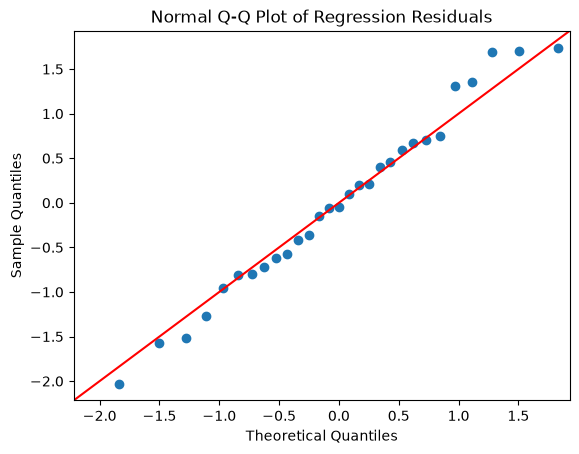

In [32]:
#Normal Q-Q Plot

sm.qqplot(
    multiple_regression_model.resid,
    line="45",
    fit=True
)

plt.title("Normal Q-Q Plot of Regression Residuals")
plt.show()

In [ ]:
ACTUAL VERSUS PREDICTED PLOT

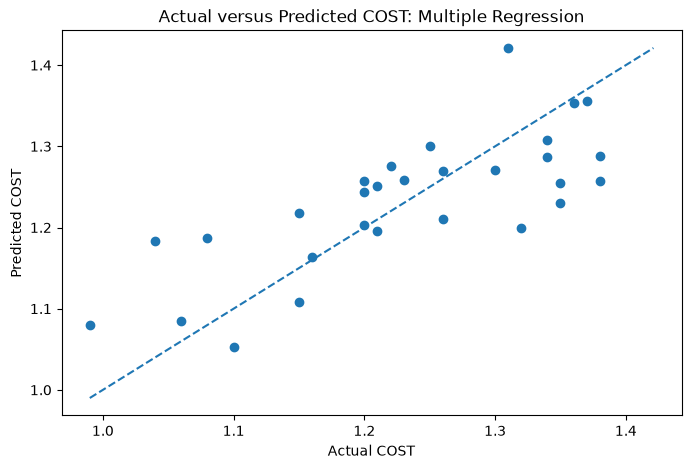

In [33]:
plt.figure(figsize=(8, 5))

plt.scatter(
    drugcost_df["COST"],
    drugcost_df["OLS_Predicted_COST"]
)

minimum_value = min(
    drugcost_df["COST"].min(),
    drugcost_df["OLS_Predicted_COST"].min()
)

maximum_value = max(
    drugcost_df["COST"].max(),
    drugcost_df["OLS_Predicted_COST"].max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel("Actual COST")
plt.ylabel("Predicted COST")
plt.title("Actual versus Predicted COST: Multiple Regression")

plt.show()

In [ ]:
Q6: Generalized Linear Model

In [34]:
glm_model = smf.glm(
    formula=(
        "COST ~ RXPM + GS + RI + COPAY "
        "+ AGE + F + MM"
    ),
    data=drugcost_df,
    family=sm.families.Gamma(
        link=sm.families.links.Log()
    )
).fit()

In [ ]:
GLM SUMMARY

In [35]:
glm_coefficients = pd.DataFrame({
    "Coefficient": glm_model.params,
    "Standard Error": glm_model.bse,
    "z Statistic": glm_model.tvalues,
    "p-value": glm_model.pvalues
})

display(glm_coefficients)

,Coefficient,Standard Error,z Statistic,p-value
Intercept,7.547212e-01,6.296616e-01,1.198614,0.230678
RXPM,1.949928e-02,9.074051e-03,2.148906,0.031642
GS,-9.654200e-03,2.333678e-03,-4.136903,0.000035
RI,2.363716e-04,1.722492e-03,0.137227,0.890852
COPAY,1.181560e-02,1.541774e-02,0.766364,0.443460
AGE,-3.108895e-02,1.229665e-02,-2.528246,0.011463
F,1.018678e-02,8.008278e-03,1.272031,0.203362
MM,2.276881e-08,3.432618e-08,0.663307,0.507134


In [ ]:
GLM PREDICTIONS and RESIDUALS

In [36]:
drugcost_df["GLM_Predicted_COST"] = (
    glm_model.predict(drugcost_df)
)

drugcost_df["GLM_Residual"] = (
    drugcost_df["COST"]
    - drugcost_df["GLM_Predicted_COST"]
)

display(
    drugcost_df[
        [
            "COST",
            "GLM_Predicted_COST",
            "GLM_Residual"
        ]
    ].head()
)

,COST,GLM_Predicted_COST,GLM_Residual
0,1.34,1.302227,0.037773
1,1.34,1.283056,0.056944
2,1.38,1.287044,0.092956
3,1.22,1.275278,-0.055278
4,1.08,1.180438,-0.100438


In [37]:
#Calculated GLM fit measures

glm_actual = drugcost_df["COST"]
glm_predictions = drugcost_df["GLM_Predicted_COST"]

glm_rmse = np.sqrt(
    np.mean(
        (glm_actual - glm_predictions) ** 2
    )
)

glm_mae = np.mean(
    np.abs(
        glm_actual - glm_predictions
    )
)

In [ ]:
#Fitted intercept-only GLM

In [38]:
glm_null_model = smf.glm(
    formula="COST ~ 1",
    data=drugcost_df,
    family=sm.families.Gamma(
        link=sm.families.links.Log()
    )
).fit()

In [39]:
#Deviamce-based pseudo-R-squared

glm_pseudo_r_squared = (
    1
    - glm_model.deviance
    / glm_null_model.deviance
)

print(
    "GLM pseudo-R-squared:",
    round(glm_pseudo_r_squared, 4)
)

print(
    "GLM deviance:",
    round(glm_model.deviance, 4)
)

print(
    "GLM Pearson chi-square:",
    round(glm_model.pearson_chi2, 4)
)

print(
    "GLM RMSE:",
    round(glm_rmse, 4)
)

print(
    "GLM MAE:",
    round(glm_mae, 4)
)

print(
    "GLM AIC:",
    round(glm_model.aic, 4)
)

GLM pseudo-R-squared: 0.5749
GLM deviance: 0.0982
GLM Pearson chi-square: 0.0978
GLM RMSE: 0.0716
GLM MAE: 0.0582
GLM AIC: -53.3707


In [ ]:
GLM Residual Plot

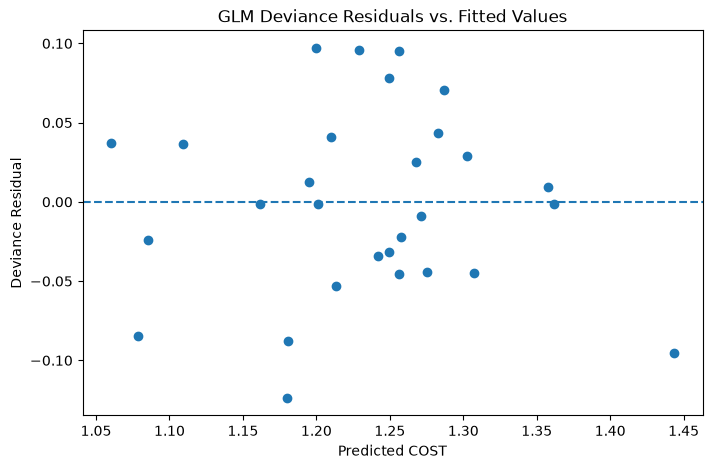

In [40]:
plt.figure(figsize=(8, 5))

plt.scatter(
    glm_model.fittedvalues,
    glm_model.resid_deviance
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted COST")
plt.ylabel("Deviance Residual")
plt.title("GLM Deviance Residuals vs. Fitted Values")

plt.show()

In [ ]:
Actual versus predicted GLM plot

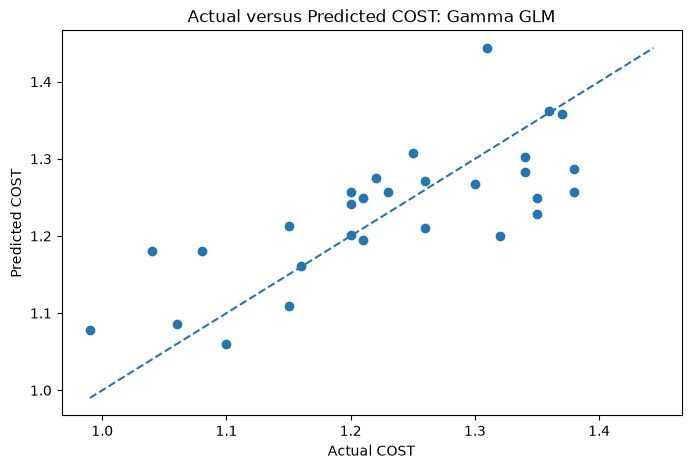

In [41]:
plt.figure(figsize=(8, 5))

plt.scatter(
    drugcost_df["COST"],
    drugcost_df["GLM_Predicted_COST"]
)

minimum_value = min(
    drugcost_df["COST"].min(),
    drugcost_df["GLM_Predicted_COST"].min()
)

maximum_value = max(
    drugcost_df["COST"].max(),
    drugcost_df["GLM_Predicted_COST"].max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel("Actual COST")
plt.ylabel("Predicted COST")
plt.title("Actual versus Predicted COST: Gamma GLM")

plt.show()

In [ ]:
Comparing multiple regression and GLM

In [42]:
model_comparison = pd.DataFrame({
    "Model": [
        "Multiple Regression",
        "Gamma GLM"
    ],
    "RMSE": [
        ols_rmse,
        glm_rmse
    ],
    "MAE": [
        ols_mae,
        glm_mae
    ],
    "AIC": [
        multiple_regression_model.aic,
        glm_model.aic
    ],
    "Fit Measure": [
        multiple_regression_model.rsquared,
        glm_pseudo_r_squared
    ],
    "Fit Measure Name": [
        "R-squared",
        "Deviance Pseudo-R-squared"
    ]
})

display(model_comparison)

,Model,RMSE,MAE,AIC,Fit Measure,Fit Measure Name
0,Multiple Regression,0.070425,0.057781,-55.587277,0.575785,R-squared
1,Gamma GLM,0.071649,0.058250,-53.370671,0.574865,Deviance Pseudo-R-squared


In [ ]:
The Gamma generalized linear model has a deviance-based pseudo-R-squared of 
approximately 0.5749, meaning it accounts for about 57.49% of the model 
deviance compared with an intercept-only model. Its RMSE is approximately 
0.0716 and its MAE is approximately 0.0582.

GS, AGE, and RXPM are statistically significant predictors in the Gamma GLM. 
The model is appropriate because COST is positive and continuous, and the 
Gamma distribution prevents negative predicted values.

The multiple regression and Gamma GLM produce similar results. However, the 
multiple regression performs slightly better based on the in-sample error 
measures. Its RMSE is approximately 0.0704 compared with 0.0716 for the GLM, 
and its MAE is approximately 0.0578 compared with 0.0582. The multiple 
regression also has the lower AIC.

Therefore, the multiple regression performs slightly better for this dataset. 
The GLM remains theoretically useful because it models positive outcomes and
multiplicative relationships.